## Eddy Alejandro Sangucho Coronel

# 01 Revisión práctica de Machine Learning

## Cargando el dataset Iris incluido en scikit-learn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

## Que representa cada instancia ?

Cada instancia representa una flor y contiene cuatro características numéricas relacionadas con las dimensiones de sus sépalos y pétalos

## Número de instancias y características

In [3]:
print("DATOS GENERALES")
print("Número de instancias:", X.shape[0])
print("Número de características:", X.shape[1])

DATOS GENERALES
Número de instancias: 150
Número de características: 4


El dataset Iris contiene 150 instancias y cuatro características numéricas.

## Nombre y significado de cada característica

In [4]:
print("\nCARACTERÍSTICAS")
for nombre in iris.feature_names:
    print(nombre)



CARACTERÍSTICAS
sepal length (cm)
sepal width (cm)
petal length (cm)
petal width (cm)


Las cuatro características del dataset son:

1. **Sepal length (cm):** longitud del sépalo, expresada en centímetros.
2. **Sepal width (cm):** ancho del sépalo, expresado en centímetros.
3. **Petal length (cm):** longitud del pétalo, expresada en centímetros.
4. **Petal width (cm):** ancho del pétalo, expresado en centímetros.

La variable objetivo es la especie de la flor. Se trata de un problema de clasificación multiclase porque existen tres categorías posibles.

## Clases y cantidad de ejemplos por clase

In [5]:
print("\nDISTRIBUCIÓN DE CLASES")
for i, nombre in enumerate(iris.target_names):
    print(f"{nombre}: {(y == i).sum()} ejemplos")


DISTRIBUCIÓN DE CLASES
setosa: 50 ejemplos
versicolor: 50 ejemplos
virginica: 50 ejemplos



Tiene tres clases de flores con 50 ejemplos por clase.Por tanto, las clases están equilibradas y ninguna especie tiene una representación mayor que las demás.

Las flores son pertenecientes a:
* Iris setosa
* Iris versicolor
* Iris virginica



## Dimensiones de la matriz de características y del vector de etiquetas.

In [6]:
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


## Tabla con cinco ejemplos y gráfico de distribución de clases

In [7]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["clase"] = [iris.target_names[i] for i in y]

print("\nCINCO PRIMEROS EJEMPLOS")
display(df.head())



CINCO PRIMEROS EJEMPLOS


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clase
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


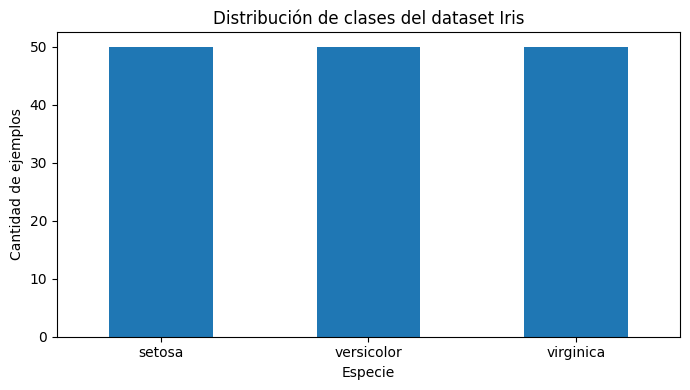

In [8]:
df["clase"].value_counts().reindex(
    iris.target_names
).plot(kind="bar", figsize=(7, 4))

plt.title("Distribución de clases del dataset Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad de ejemplos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Esta distribución permite comparar clasificadores sin que exista un desequilibrio inicial en la cantidad de ejemplos por clase. Sin embargo, esto no garantiza que todas las clases sean igualmente fáciles de predecir.

# 2.Comparación de clasificadores

## Predicciones Iniciales

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

    La regresión logística, el SVM lineal y el MLP suelen ser sensibles a las escalas de las características. Aunque kNN no forma parte de los siete clasificadores de esta sección, también es importante considerarlo como ejemplo.Estandarizar las características puede mejorar el entrenamiento y evitar que las variables con mayor escala dominen el cálculo.

    Gaussian Naive Bayes, los árboles de decisión, Random Forest y Gradient Boosting generalmente no necesitan escalamiento.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

    Espero que el SVM lineal produzca fronteras de decisión relativamente simples, porque utiliza separaciones lineales entre las clases.La regresión logística multiclase también utiliza fronteras lineales en el espacio de características.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

    No podemos asegurar cuál será el mejor porque el rendimiento depende de las características del dataset, la relación entre las variables y las clases, los hiperparámetros y la capacidad de generalización de cada modelo. Por eso, debemos comparar sus resultados con las mismas particiones de datos y métricas.

# Librerias a utilizar

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [10]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier


In [11]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

## Preparación de los datos

Separaremos Iris en tres conjuntos:
- Entrenamiento (60 %): para aprender los parámetros de los modelos.
- Validación (20 %): para comparar modelos y elegir hiperparámetros.
- Prueba (20 %): para evaluar las configuraciones finales.

Utilizaremos stratify=y para mantener aproximadamente la misma proporción de especies en cada partición y random_state=42 para reproducir los resultados.

In [12]:
# Primera separación: 80 % desarrollo, 20 % prueba
X_desarrollo, X_test, y_desarrollo, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



In [13]:
# Segunda separación: 60 % entrenamiento, 20 % validación, 20 % prueba
X_train, X_val, y_train, y_val = train_test_split(
    X_desarrollo, y_desarrollo,
    test_size=0.25,
    random_state=42,
    stratify=y_desarrollo
)

In [14]:
print("Tamaño de los conjuntos:")
print("Entrenamiento:", X_train.shape[0])
print("Validación:", X_val.shape[0])
print("Prueba:", X_test.shape[0])

Tamaño de los conjuntos:
Entrenamiento: 90
Validación: 30
Prueba: 30


In [15]:
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nEjemplos por clase en entrenamiento:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nEjemplos por clase en validación:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nEjemplos por clase en prueba:")
print(pd.Series(y_test).value_counts().sort_index())


Entrenamiento: (90, 4)
Validación: (30, 4)
Prueba: (30, 4)

Ejemplos por clase en entrenamiento:
0    30
1    30
2    30
Name: count, dtype: int64

Ejemplos por clase en validación:
0    10
1    10
2    10
Name: count, dtype: int64

Ejemplos por clase en prueba:
0    10
1    10
2    10
Name: count, dtype: int64


### Justificación

Se utiliza una separación estratificada para conservar la representación de las tres especies en los conjuntos de entrenamiento, validación y prueba. La semilla aleatoria permite reproducir la partición.

La validación sirve para tomar decisiones sobre los hiperparámetros, mientras que el conjunto de prueba se reserva para la evaluación final. De esta manera, evitamos ajustar los modelos específicamente a los ejemplos de prueba y obtenemos una evaluación más independiente de su capacidad de generalización.


# 2.1 y 2.2 Configuraciones iniciales y entrenamiento

Utilizaremos StandardScaler dentro de un Pipeline. Esto es importante porque el escalador debe aprender sus parámetros únicamente a partir de los datos de entrenamiento de cada experimento. Aunque los árboles no necesitan estandarización, utilizaremos el mismo protocolo de preparación para todos, como solicita la práctica.

In [16]:
modelos_iniciales = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Regresión logística": LogisticRegression(
        C=1.0, max_iter=2000, random_state=42
    ),
    "SVM lineal": LinearSVC(
        C=1.0, max_iter=10000, random_state=42
    ),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=None, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(50,),
        alpha=0.0001,
        max_iter=2000,
        random_state=42
    )
}

resultados_iniciales = []
pipelines_iniciales = {}



# 2.3 Comparación accuracy y F1 macro en validación

In [17]:
for nombre, modelo in modelos_iniciales.items():
    pipeline = Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", modelo)
    ])

    pipeline.fit(X_train, y_train)
    pred_val = pipeline.predict(X_val)

    accuracy = accuracy_score(y_val, pred_val)
    f1 = f1_score(y_val, pred_val, average="macro")

    pipelines_iniciales[nombre] = pipeline

    resultados_iniciales.append({
        "Modelo": nombre,
        "Accuracy validación": accuracy,
        "F1 macro validación": f1
    })

tabla_inicial = pd.DataFrame(resultados_iniciales)
tabla_inicial.sort_values(
    by="F1 macro validación", ascending=False
).round(4)

,Modelo,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,0.9333,0.9333
1,Regresión logística,0.9333,0.9333
3,Árbol de decisión,0.9333,0.9333
6,MLP,0.9333,0.9333
4,Random Forest,0.9333,0.9333
5,Gradient Boosting,0.9000,0.8997
2,SVM lineal,0.8333,0.8329


### Interpretación inicial
Después de ejecutar la celda, se observa las dos métricas de validación.
Accuracy mide la proporción total de predicciones correctas, mientras que F1 macro calcula el F1 de cada clase y promedia los tres resultados con el mismo peso.

Todavía no debemos declarar un ganador definitivo: primero realizaremos ajustes limitados y luego evaluaremos las configuraciones congeladas en prueba.

# 2.4 Ajustes limitados usando validación

In [18]:
from sklearn.base import clone

candidatos = {
    "Gaussian Naive Bayes": [
        GaussianNB(var_smoothing=1e-9),
        GaussianNB(var_smoothing=1e-8),
        GaussianNB(var_smoothing=1e-7)
    ],
    "Regresión logística": [
        LogisticRegression(C=0.1, max_iter=2000, random_state=42),
        LogisticRegression(C=1.0, max_iter=2000, random_state=42),
        LogisticRegression(C=10.0, max_iter=2000, random_state=42)
    ],
    "SVM lineal": [
        LinearSVC(C=0.1, max_iter=10000, random_state=42),
        LinearSVC(C=1.0, max_iter=10000, random_state=42),
        LinearSVC(C=10.0, max_iter=10000, random_state=42)
    ],
    "Árbol de decisión": [
        DecisionTreeClassifier(max_depth=2, random_state=42),
        DecisionTreeClassifier(max_depth=3, random_state=42),
        DecisionTreeClassifier(max_depth=None, random_state=42)
    ],
    "Random Forest": [
        RandomForestClassifier(
            n_estimators=100, max_depth=3, random_state=42
        ),
        RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),
        RandomForestClassifier(
            n_estimators=200, max_depth=5, random_state=42
        )
    ],
    "Gradient Boosting": [
        GradientBoostingClassifier(
            n_estimators=50, learning_rate=0.1,
            max_depth=2, random_state=42
        ),
        GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.1,
            max_depth=2, random_state=42
        ),
        GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.05,
            max_depth=3, random_state=42
        )
    ],
    "MLP": [
        MLPClassifier(
            hidden_layer_sizes=(20,), alpha=0.001,
            max_iter=3000, random_state=42
        ),
        MLPClassifier(
            hidden_layer_sizes=(50,), alpha=0.01,
            max_iter=3000, random_state=42
        ),
        MLPClassifier(
            hidden_layer_sizes=(50, 25), alpha=0.001,
            max_iter=3000, random_state=42
        )
    ]
}

mejores_modelos = {}
resultados_ajuste = []

for nombre, lista_modelos in candidatos.items():
    candidatos_evaluados = []

    for modelo in lista_modelos:
        pipeline = Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", clone(modelo))
        ])

        pipeline.fit(X_train, y_train)
        pred_val = pipeline.predict(X_val)

        acc = accuracy_score(y_val, pred_val)
        f1 = f1_score(y_val, pred_val, average="macro")

        candidatos_evaluados.append({
            "modelo": modelo,
            "accuracy": acc,
            "f1_macro": f1
        })

    # Seleccionar usando solo los resultados de validación
    mejor = max(
        candidatos_evaluados,
        key=lambda r: (r["f1_macro"], r["accuracy"])
    )

    mejores_modelos[nombre] = mejor["modelo"]

    resultados_ajuste.append({
        "Modelo": nombre,
        "Mejor configuración": str(mejor["modelo"]),
        "Accuracy validación": mejor["accuracy"],
        "F1 macro validación": mejor["f1_macro"]
    })

tabla_ajuste = pd.DataFrame(resultados_ajuste)

tabla_ajuste[
    ["Modelo", "Accuracy validación", "F1 macro validación"]
].sort_values(
    "F1 macro validación", ascending=False
).round(4)

,Modelo,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,0.9333,0.9333
1,Regresión logística,0.9333,0.9333
3,Árbol de decisión,0.9333,0.9333
5,Gradient Boosting,0.9333,0.9333
4,Random Forest,0.9333,0.9333
6,MLP,0.9333,0.9333
2,SVM lineal,0.8667,0.8667


### Interpretación
Los hiperparámetros controlan cómo aprende el modelo. Por ejemplo, C controla la regularización de la regresión logística y el SVM, max_depth limita la profundidad de los árboles y alpha regula la penalización de los pesos del MLP.

# 2.5 y 2.6 Evaluación final en prueba

In [19]:
X_train_final = pd.concat([
    pd.DataFrame(X_train, columns=iris.feature_names),
    pd.DataFrame(X_val, columns=iris.feature_names)
], ignore_index=True).values

y_train_final = pd.concat([
    pd.Series(y_train),
    pd.Series(y_val)
], ignore_index=True).values

modelos_finales = {}
predicciones_test = {}
resultados_test = []

for nombre, modelo in mejores_modelos.items():
    pipeline = Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", clone(modelo))
    ])

    pipeline.fit(X_train_final, y_train_final)
    pred_test = pipeline.predict(X_test)

    modelos_finales[nombre] = pipeline
    predicciones_test[nombre] = pred_test

    resultados_test.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": str(modelo.get_params()),
        "Accuracy de prueba": accuracy_score(y_test, pred_test),
        "F1 macro de prueba": f1_score(
            y_test, pred_test, average="macro"
        )
    })

tabla_test = pd.DataFrame(resultados_test)

tabla_test[
    [
        "Modelo",
        "Transformación",
        "Hiperparámetros principales",
        "Accuracy de prueba",
        "F1 macro de prueba"
    ]
].sort_values(
    "F1 macro de prueba", ascending=False
).round(4)



,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,"{'priors': None, 'var_smoothing': 1e-09}",0.9667,0.9666
6,MLP,StandardScaler,"{'activation': 'relu', 'alpha': 0.001, 'batch_...",0.9667,0.9666
4,Random Forest,StandardScaler,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w...",0.9667,0.9666
2,SVM lineal,StandardScaler,"{'C': 10.0, 'class_weight': None, 'dual': 'aut...",0.9333,0.9333
1,Regresión logística,StandardScaler,"{'C': 1.0, 'class_weight': None, 'dual': False...",0.9333,0.9333
3,Árbol de decisión,StandardScaler,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit...",0.9333,0.9333
5,Gradient Boosting,StandardScaler,"{'ccp_alpha': 0.0, 'criterion': 'friedman_mse'...",0.9333,0.9333


# Matrices de confusión de Naive Bayes, SVM y MLP.

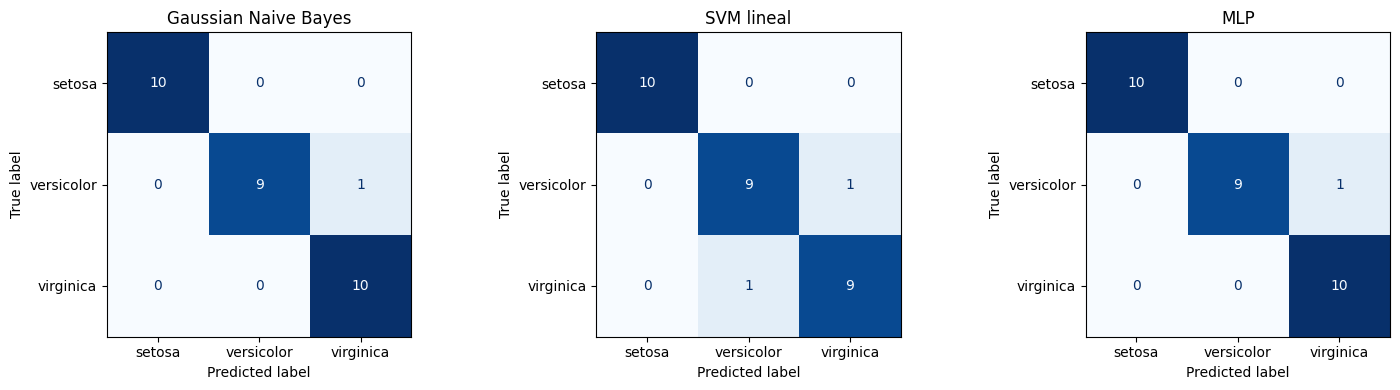

In [20]:
modelos_confusion = [
    "Gaussian Naive Bayes",
    "SVM lineal",
    "MLP"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, nombre in zip(axes, modelos_confusion):
    matriz = confusion_matrix(
        y_test,
        predicciones_test[nombre],
        labels=[0, 1, 2]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=iris.target_names
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

# Interpretación

## Identificar el mejor modelo

In [21]:

mejor_accuracy = tabla_test.loc[
    tabla_test["Accuracy de prueba"].idxmax()
]

mejor_f1 = tabla_test.loc[
    tabla_test["F1 macro de prueba"].idxmax()
]

print("Mejor modelo según Accuracy:")
print(mejor_accuracy[[
    "Modelo", "Accuracy de prueba", "F1 macro de prueba"
]])

print("\nMejor modelo según F1 macro:")
print(mejor_f1[[
    "Modelo", "Accuracy de prueba", "F1 macro de prueba"
]])


Mejor modelo según Accuracy:
Modelo                Gaussian Naive Bayes
Accuracy de prueba                0.966667
F1 macro de prueba                0.966583
Name: 0, dtype: object

Mejor modelo según F1 macro:
Modelo                Gaussian Naive Bayes
Accuracy de prueba                0.966667
F1 macro de prueba                0.966583
Name: 0, dtype: object


**1. ¿Cuál fue el modelo con el mejor desempeño?**

Según los resultados obtenidos, el mejor modelo según accuracy fue  Gaussian Naive Bayes, con un valor de 0.966667. Según F1 macro, el mejor fue Gaussian Naive Bayes, con un valor de 0.966583 . Esto permite comparar tanto la proporción total de aciertos como el rendimiento promedio entre las tres clases.

**2. ¿Cuál fue el modelo más sencillo de programar?**

Gaussian Naive Bayes fue uno de los modelos más sencillos de implementar, porque requiere pocos hiperparámetros y utiliza una estructura probabilística relativamente simple. Por otra parte, su facilidad de implementación no garantiza que tenga el mejor rendimiento.

**3. ¿Accuracy y F1 macro cuentan la misma historia?**

No necesariamente. Accuracy mide la proporción de predicciones correctas sobre el total de ejemplos, mientras que F1 macro calcula el F1 de cada clase y obtiene su promedio sin ponderarlo por la cantidad de ejemplos. Si un modelo funciona especialmente mal en una clase, F1 macro puede reflejarlo mejor.

**4. ¿Cuál es la diferencia entre las métricas macro y micro?**

La métrica macro calcula una puntuación por clase y después promedia todas las puntuaciones con el mismo peso. La métrica micro agrega los verdaderos positivos, falsos positivos y falsos negativos de todas las clases antes de calcular la métrica.

En una clasificación multiclase de etiqueta única, la precisión micro, el recall micro, el F1 micro y accuracy coinciden. En Iris, como las clases están equilibradas, accuracy y F1 macro pueden presentar resultados parecidos, aunque no tienen por qué ser idénticos.

**5. ¿Qué aporta el MLP frente a un modelo lineal?**

El MLP puede aprender relaciones no lineales mediante capas ocultas y funciones de activación. Esto le permite representar fronteras de decisión más complejas que un clasificador estrictamente lineal. Sin embargo, requiere ajustar parámetros como el número de neuronas, la regularización y las iteraciones de entrenamiento, y no garantiza mejores resultados en todos los datasets.

# Análisis de dos errores de clasificación

In [22]:

errores = []

for nombre, pred in predicciones_test.items():
    indices_error = [
        i for i in range(len(y_test))
        if y_test[i] != pred[i]
    ]

    for i in indices_error:
        errores.append({
            "Modelo": nombre,
            "Índice en prueba": i,
            "Clase real": iris.target_names[y_test[i]],
            "Clase predicha": iris.target_names[pred[i]],
            "Sepal length (cm)": X_test[i, 0],
            "Sepal width (cm)": X_test[i, 1],
            "Petal length (cm)": X_test[i, 2],
            "Petal width (cm)": X_test[i, 3]
        })

df_errores = pd.DataFrame(errores)

if len(df_errores) >= 2:
    display(df_errores.head(2).round(3))
elif len(df_errores) > 0:
    display(df_errores.round(3))
else:
    print("Ninguno de los siete modelos cometió errores en prueba.")


,Modelo,Índice en prueba,Clase real,Clase predicha,Sepal length (cm),Sepal width (cm),Petal length (cm),Petal width (cm)
0,Gaussian Naive Bayes,25,versicolor,virginica,6.7,3.0,5.0,1.7
1,Regresión logística,23,virginica,versicolor,6.1,2.6,5.6,1.4


Para analizar dos errores, se comparan las características de cada flor con su clase real y la clase predicha por el modelo.

Si las mediciones de dos especies son similares, esto puede ayudar a explicar por qué el clasificador las confunde. Sin embargo, las características observadas no demuestran por sí solas la causa exacta del error.

Además, dos errores no son suficientes para determinar el comportamiento general del modelo. Para sacar conclusiones más sólidas, sería necesario estudiar el conjunto completo de errores, las fronteras de decisión y el rendimiento de cada clase.

### Conclusión

En este experimento se compararon siete clasificadores utilizando el mismo dataset y una separación común de entrenamiento, validación y prueba. Los modelos se evaluaron mediante accuracy y F1 macro, y sus configuraciones se seleccionaron usando exclusivamente validación.

Los resultados permiten estudiar las diferencias entre modelos probabilísticos, lineales, basados en árboles y redes neuronales. También muestran la importancia de estandarizar las características cuando corresponde, controlar los hiperparámetros y reservar los datos de prueba para una evaluación final independiente.

El mejor modelo debe identificarse a partir de las métricas obtenidas, considerando tanto su rendimiento general como los errores observados. Un buen resultado en este dataset no garantiza que el modelo tenga el mismo rendimiento con datos nuevos procedentes de otros contextos.

#3. Comparación de modelos de regresión

# 3.1 Carga y descripción del dataset

### Dataset Diabetes

El dataset Diabetes de scikit-learn es un conjunto de datos de regresión que contiene información de 442 pacientes y diez características numéricas. El objetivo es predecir una medida cuantitativa de la progresión de la diabetes aproximadamente un año después de la evaluación inicial.

Las diez características representan variables clínicas y antropométricas, como edad, sexo, índice de masa corporal, presión arterial y seis mediciones relacionadas con el suero sanguíneo.

Es importante tener en cuenta que las características del dataset ya fueron transformadas y estandarizadas durante su preparación. Por tanto, sus valores no deben interpretarse automáticamente como edades en años, presiones en unidades clínicas originales o concentraciones sanguíneas reales.

El problema consiste en una regresión supervisada, ya que la variable objetivo es numérica y no una categoría.

In [23]:
from sklearn.datasets import load_diabetes

In [24]:
diabetes = load_diabetes()

X_reg = diabetes.data
y_reg = diabetes.target


In [25]:
df_diabetes = pd.DataFrame(
    X_reg,
    columns=diabetes.feature_names
)

df_diabetes["objetivo"] = y_reg

print("Número de instancias:", X_reg.shape[0])
print("Número de características:", X_reg.shape[1])
print("Dimensiones de X:", X_reg.shape)
print("Dimensiones de y:", y_reg.shape)

Número de instancias: 442
Número de características: 10
Dimensiones de X: (442, 10)
Dimensiones de y: (442,)


In [26]:
print("\nCaracterísticas:")
for nombre, descripcion in zip(
    diabetes.feature_names,
    diabetes.DESCR.split(":", 1)[0:1] * len(diabetes.feature_names)
):
    print("-", nombre)


Características:
- age
- sex
- bmi
- bp
- s1
- s2
- s3
- s4
- s5
- s6


In [27]:
print("\nDescripción oficial del dataset:")
print(diabetes.DESCR)

print("\nPrimeros cinco ejemplos:")
display(df_diabetes.head())


Descripción oficial del dataset:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of t

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,objetivo
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


# Significado de las variables

Las diez características disponibles son:

age: edad.

sex: sexo.

bmi: índice de masa corporal.

bp: presión arterial media.

s1: colesterol total.

s2: lipoproteínas de baja densidad (LDL).

s3: lipoproteínas de alta densidad (HDL).

s4: relación entre colesterol total y HDL.

s5: logaritmo de los triglicéridos.

s6: glucosa en sangre.

El objetivo es una medida cuantitativa de la progresión de la diabetes. Las características están normalizadas o transformadas, por lo que sus números no representan directamente las unidades clínicas originales.

Este conjunto permite comparar modelos capaces de aprender relaciones lineales y no lineales entre las características y el objetivo.

# 3.2 Predicción Inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No. Un modelo más flexible puede aprender relaciones complejas entre las características y el objetivo, pero también puede ajustarse demasiado a los datos de entrenamiento y presentar sobreajuste. En ese caso, su error de entrenamiento puede ser bajo, mientras que su error en datos nuevos es mayor.

Por eso, la flexibilidad del modelo no garantiza una mejor generalización. Es necesario comparar los resultados de entrenamiento y validación, controlar los hiperparámetros y evaluar el modelo final con datos de prueba que no se hayan utilizado para seleccionarlo.


# 3.3 Separación de los datos

Usaremos la misma proporción que en la sección anterior: 60 % para entrenamiento, 20 % para validación y 20 % para prueba.

In [28]:
X_desarrollo_reg, X_test_reg, y_desarrollo_reg, y_test_reg = (
    train_test_split(
        X_reg, y_reg,
        test_size=0.20,
        random_state=42
    )
)

X_train_reg, X_val_reg, y_train_reg, y_val_reg = (
    train_test_split(
        X_desarrollo_reg, y_desarrollo_reg,
        test_size=0.25,
        random_state=42
    )
)

In [29]:
print("Entrenamiento:", X_train_reg.shape)
print("Validación:", X_val_reg.shape)
print("Prueba:", X_test_reg.shape)


Entrenamiento: (264, 10)
Validación: (89, 10)
Prueba: (89, 10)


# 3.4 Entrenamiento de los ocho modelos

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

modelos_reg_iniciales = {
    "Regresión lineal": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Lasso": Lasso(alpha=0.1, max_iter=20000),

    "kNN": KNeighborsRegressor(n_neighbors=5, weights="uniform"),

    "Árbol de regresión": DecisionTreeRegressor(
        max_depth=4, random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=5, random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05,
        max_depth=2, random_state=42
    ),

    "MLP": MLPRegressor(
        hidden_layer_sizes=(50,),
        alpha=0.01,
        max_iter=3000,
        random_state=42
    )
}

## Entrear y comparar en validación

Usaremos MAE, RMSE y R². El MAE y RMSE deben ser menores cuando las predicciones son mejores, mientras que un R² mayor suele indicar un mejor ajuste.

In [31]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def crear_pipeline_regresion(modelo):
    return Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", clone(modelo))
    ])

resultados_reg_iniciales = []
pipelines_reg_iniciales = {}

for nombre, modelo in modelos_reg_iniciales.items():
    pipeline = crear_pipeline_regresion(modelo)

    pipeline.fit(X_train_reg, y_train_reg)
    pred_val = pipeline.predict(X_val_reg)

    mae = mean_absolute_error(y_val_reg, pred_val)
    rmse = mean_squared_error(y_val_reg, pred_val) ** 0.5
    r2 = r2_score(y_val_reg, pred_val)

    pipelines_reg_iniciales[nombre] = pipeline

    resultados_reg_iniciales.append({
        "Modelo": nombre,
        "MAE validación": mae,
        "RMSE validación": rmse,
        "R² validación": r2
    })

tabla_reg_inicial = pd.DataFrame(resultados_reg_iniciales)

display(
    tabla_reg_inicial
    .sort_values("RMSE validación")
    .round(3)
)



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE validación,RMSE validación,R² validación
2,Lasso,42.642,51.100,0.523
1,Ridge,42.723,51.103,0.523
0,Regresión lineal,42.939,51.194,0.522
7,MLP,43.599,52.993,0.487
6,Gradient Boosting,43.264,53.289,0.482
5,Random Forest,43.930,54.460,0.459
3,kNN,45.292,56.833,0.410
4,Árbol de regresión,47.237,59.761,0.348


# 3.5 Ajuste limitado de hiperparametros

In [32]:

candidatos_reg = {
    "Regresión lineal": [
        LinearRegression()
    ],
    "Ridge": [
        Ridge(alpha=0.1),
        Ridge(alpha=1.0),
        Ridge(alpha=10.0)
    ],
    "Lasso": [
        Lasso(alpha=0.01, max_iter=20000),
        Lasso(alpha=0.1, max_iter=20000),
        Lasso(alpha=1.0, max_iter=20000)
    ],
    "kNN": [
        KNeighborsRegressor(n_neighbors=5),
        KNeighborsRegressor(n_neighbors=10),
        KNeighborsRegressor(n_neighbors=20)
    ],
    "Árbol de regresión": [
        DecisionTreeRegressor(max_depth=2, random_state=42),
        DecisionTreeRegressor(max_depth=4, random_state=42),
        DecisionTreeRegressor(max_depth=6, random_state=42)
    ],
    "Random Forest": [
        RandomForestRegressor(
            n_estimators=200, max_depth=3, random_state=42
        ),
        RandomForestRegressor(
            n_estimators=200, max_depth=5, random_state=42
        ),
        RandomForestRegressor(
            n_estimators=200, max_depth=None, random_state=42
        )
    ],
    "Gradient Boosting": [
        GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.05,
            max_depth=2, random_state=42
        ),
        GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.1,
            max_depth=2, random_state=42
        ),
        GradientBoostingRegressor(
            n_estimators=200, learning_rate=0.05,
            max_depth=2, random_state=42
        )
    ],
    "MLP": [
        MLPRegressor(
            hidden_layer_sizes=(20,), alpha=0.01,
            max_iter=4000, random_state=42
        ),
        MLPRegressor(
            hidden_layer_sizes=(50,), alpha=0.1,
            max_iter=4000, random_state=42
        ),
        MLPRegressor(
            hidden_layer_sizes=(50, 25), alpha=0.01,
            max_iter=4000, random_state=42
        )
    ]
}

mejores_reg = {}
resultados_ajuste_reg = []

for nombre, lista_modelos in candidatos_reg.items():
    evaluaciones = []

    for modelo in lista_modelos:
        pipeline = crear_pipeline_regresion(modelo)
        pipeline.fit(X_train_reg, y_train_reg)

        pred = pipeline.predict(X_val_reg)

        evaluaciones.append({
            "modelo": modelo,
            "mae": mean_absolute_error(y_val_reg, pred),
            "rmse": mean_squared_error(y_val_reg, pred) ** 0.5,
            "r2": r2_score(y_val_reg, pred)
        })

    mejor = min(
        evaluaciones,
        key=lambda r: (r["rmse"], -r["r2"])
    )

    mejores_reg[nombre] = mejor["modelo"]

    resultados_ajuste_reg.append({
        "Modelo": nombre,
        "Configuración": str(mejor["modelo"]),
        "MAE validación": mejor["mae"],
        "RMSE validación": mejor["rmse"],
        "R² validación": mejor["r2"]
    })

tabla_ajuste_reg = pd.DataFrame(resultados_ajuste_reg)

display(
    tabla_ajuste_reg[
        ["Modelo", "MAE validación", "RMSE validación", "R² validación"]
    ].sort_values("RMSE validación").round(3)
)



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (4000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (4000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE validación,RMSE validación,R² validación
2,Lasso,42.470,51.060,0.524
1,Ridge,42.723,51.103,0.523
0,Regresión lineal,42.939,51.194,0.522
6,Gradient Boosting,43.264,53.289,0.482
7,MLP,43.890,53.354,0.480
5,Random Forest,43.568,53.991,0.468
3,kNN,45.558,54.554,0.457
4,Árbol de regresión,46.680,58.781,0.369


# 3.6 Evaluación final en prueba

Congeladas las configuraciones, reuniremos los conjuntos de entrenamiento y validación para ajustar los modelos finales. El conjunto de prueba permanece separado hasta este punto.

In [33]:

import numpy as np

X_train_final_reg = np.concatenate(
    [X_train_reg, X_val_reg], axis=0
)
y_train_final_reg = np.concatenate(
    [y_train_reg, y_val_reg], axis=0
)

modelos_finales_reg = {}
predicciones_test_reg = {}
resultados_test_reg = []

for nombre, modelo in mejores_reg.items():
    pipeline = crear_pipeline_regresion(modelo)

    pipeline.fit(X_train_final_reg, y_train_final_reg)
    pred_test = pipeline.predict(X_test_reg)

    modelos_finales_reg[nombre] = pipeline
    predicciones_test_reg[nombre] = pred_test

    resultados_test_reg.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test_reg, pred_test),
        "RMSE": mean_squared_error(y_test_reg, pred_test) ** 0.5,
        "R²": r2_score(y_test_reg, pred_test)
    })

tabla_test_reg = pd.DataFrame(resultados_test_reg)

display(
    tabla_test_reg.sort_values("RMSE").round(3)
)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (4000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE,RMSE,R²
7,MLP,41.006,51.819,0.493
6,Gradient Boosting,42.590,52.395,0.482
5,Random Forest,42.582,52.729,0.475
2,Lasso,42.803,53.147,0.467
1,Ridge,42.812,53.777,0.454
0,Regresión lineal,42.794,53.853,0.453
3,kNN,45.454,55.212,0.425
4,Árbol de regresión,49.365,61.119,0.295


# 3.7 Gráficos de valores reales frente a predicciones

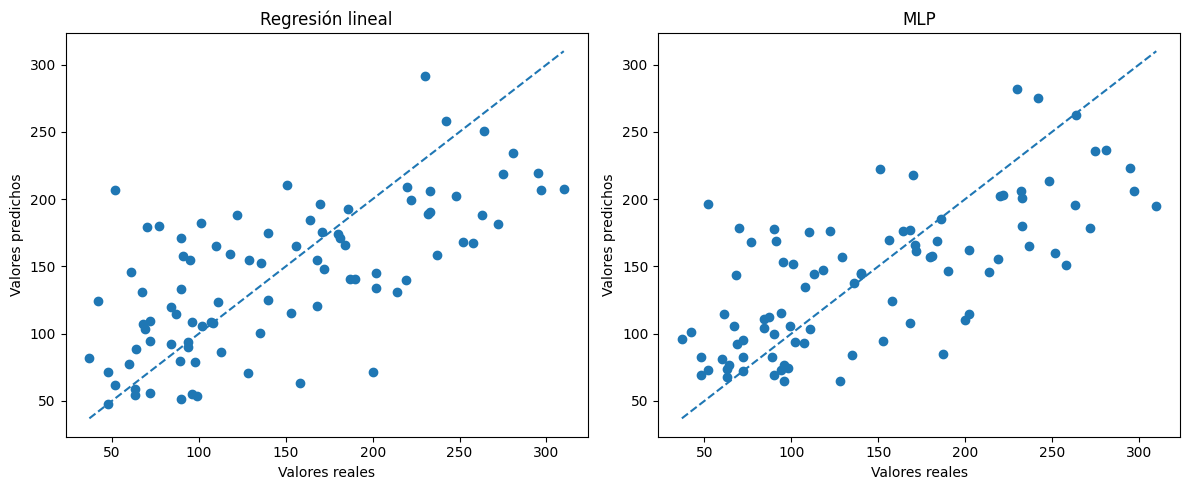

In [34]:

modelos_graficos = ["Regresión lineal", "MLP"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nombre in zip(axes, modelos_graficos):
    reales = y_test_reg
    predichos = predicciones_test_reg[nombre]

    ax.scatter(reales, predichos)

    minimo = min(reales.min(), predichos.min())
    maximo = max(reales.max(), predichos.max())

    ax.plot([minimo, maximo], [minimo, maximo], linestyle="--")

    ax.set_title(nombre)
    ax.set_xlabel("Valores reales")
    ax.set_ylabel("Valores predichos")

plt.tight_layout()
plt.show()


Interpretación: cuanto más cerca estén los puntos de la diagonal, más cercanas son las predicciones a los valores reales. Los puntos alejados de ella indican errores mayores.

# 3.8 Gráficos de residuos

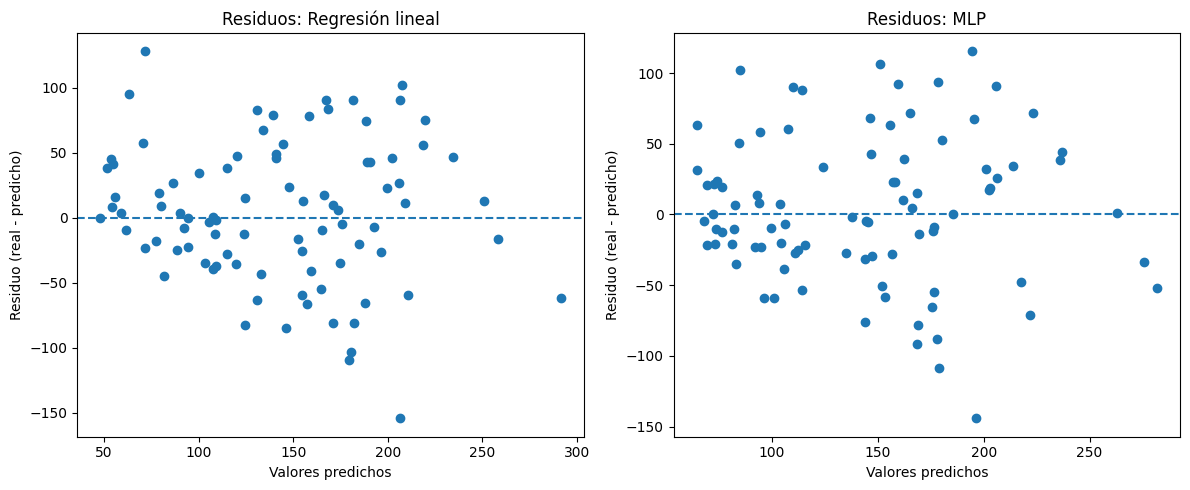

In [35]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nombre in zip(axes, modelos_graficos):
    reales = y_test_reg
    predichos = predicciones_test_reg[nombre]
    residuos = reales - predichos

    ax.scatter(predichos, residuos)
    ax.axhline(0, linestyle="--")

    ax.set_title(f"Residuos: {nombre}")
    ax.set_xlabel("Valores predichos")
    ax.set_ylabel("Residuo (real - predicho)")

plt.tight_layout()
plt.show()


# 3.9 Dos ejemplos con errores absolutos grandes

In [36]:

for nombre in modelos_graficos:
    predichos = predicciones_test_reg[nombre]
    errores_abs = np.abs(y_test_reg - predichos)

    indices = np.argsort(errores_abs)[-2:][::-1]

    tabla_errores = pd.DataFrame({
        "Índice en prueba": indices,
        "Valor real": y_test_reg[indices],
        "Predicción": predichos[indices],
        "Error absoluto": errores_abs[indices]
    })

    print(f"\nDos errores absolutos grandes: {nombre}")
    display(tabla_errores.round(2))



Dos errores absolutos grandes: Regresión lineal


,Índice en prueba,Valor real,Predicción,Error absoluto
0,61,52.0,206.49,154.49
1,46,200.0,71.67,128.33



Dos errores absolutos grandes: MLP


,Índice en prueba,Valor real,Predicción,Error absoluto
0,61,52.0,196.22,144.22
1,20,310.0,194.53,115.47


### Interpretación de errores grandes

Los ejemplos con errores absolutos grandes representan observaciones para las cuales el modelo presenta mayor dificultad de predicción. Pueden existir varias explicaciones, como relaciones no lineales que el modelo no logra representar, variabilidad entre los pacientes, información relevante que no está disponible en las características o limitaciones del propio algoritmo.

Estos ejemplos permiten identificar predicciones poco precisas, pero no demuestran por sí solos la causa del error. Para investigarla sería necesario analizar las características de las observaciones, los patrones de residuos y el comportamiento general del modelo.

# 3.10 Regularización : Ridge y Lasso

La regularización penaliza los coeficientes del modelo para limitar su magnitud y ayudar a evitar el sobreajuste.
- Ridge (L2): reduce los coeficientes, generalmente sin convertirlos exactamente en cero.
- Lasso (L1): puede convertir algunos coeficientes en cero, lo que permite obtener modelos más simples.

In [37]:

from sklearn.linear_model import Ridge, Lasso

alphas = [0.001, 0.01, 0.1, 1.0, 10.0]

resultados_regularizacion = []
modelos_regularizacion = {}

for nombre, clase_modelo in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for alpha in alphas:
        modelo = Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", clase_modelo(
                alpha=alpha,
                max_iter=30000
            ) if nombre == "Lasso" else clase_modelo(alpha=alpha))
        ])

        modelo.fit(X_train_reg, y_train_reg)

        pred_train = modelo.predict(X_train_reg)
        pred_val = modelo.predict(X_val_reg)

        estimador = modelo.named_steps["modelo"]
        coeficientes = estimador.coef_

        resultados_regularizacion.append({
            "Modelo": nombre,
            "Alpha": alpha,
            "MAE entrenamiento": mean_absolute_error(
                y_train_reg, pred_train
            ),
            "RMSE entrenamiento": mean_squared_error(
                y_train_reg, pred_train
            ) ** 0.5,
            "RMSE validación": mean_squared_error(
                y_val_reg, pred_val
            ) ** 0.5,
            "Suma absoluta coeficientes": np.abs(
                coeficientes
            ).sum(),
            "Coeficientes nulos": np.sum(
                np.isclose(coeficientes, 0)
            )
        })

        modelos_regularizacion[(nombre, alpha)] = modelo

tabla_regularizacion = pd.DataFrame(resultados_regularizacion)

display(tabla_regularizacion.round(3))


,Modelo,Alpha,MAE entrenamiento,RMSE entrenamiento,RMSE validación,Suma absoluta coeficientes,Coeficientes nulos
0,Ridge,0.001,43.794,54.610,51.193,198.217,0
1,Ridge,0.010,43.793,54.610,51.192,197.670,0
2,Ridge,0.100,43.792,54.611,51.174,192.447,0
3,Ridge,1.000,43.791,54.644,51.103,156.990,0
4,Ridge,10.000,43.936,54.843,51.160,108.883,0
5,Lasso,0.001,43.794,54.610,51.192,197.799,0
6,Lasso,0.010,43.795,54.611,51.178,193.487,0
7,Lasso,0.100,43.820,54.654,51.100,150.425,0
8,Lasso,1.000,44.115,54.912,51.060,100.612,1
9,Lasso,10.000,48.254,58.425,53.151,52.749,6


### Visualización de errores de entrenamiento y validación

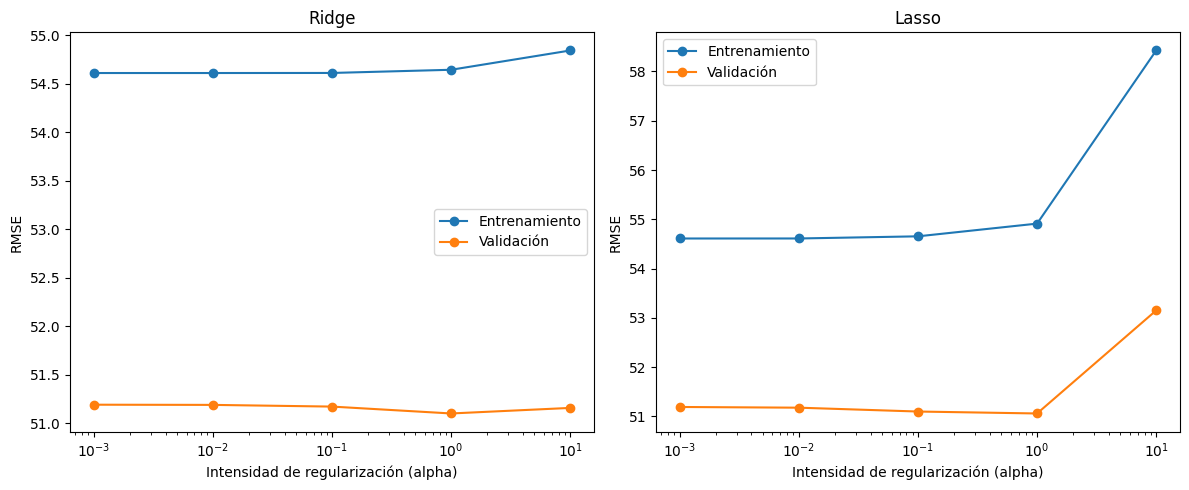

In [38]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nombre in zip(axes, ["Ridge", "Lasso"]):
    datos = tabla_regularizacion[
        tabla_regularizacion["Modelo"] == nombre
    ]

    ax.plot(
        datos["Alpha"],
        datos["RMSE entrenamiento"],
        marker="o",
        label="Entrenamiento"
    )

    ax.plot(
        datos["Alpha"],
        datos["RMSE validación"],
        marker="o",
        label="Validación"
    )

    ax.set_xscale("log")
    ax.set_title(nombre)
    ax.set_xlabel("Intensidad de regularización (alpha)")
    ax.set_ylabel("RMSE")
    ax.legend()

plt.tight_layout()
plt.show()


### Comparación de los coeficientes

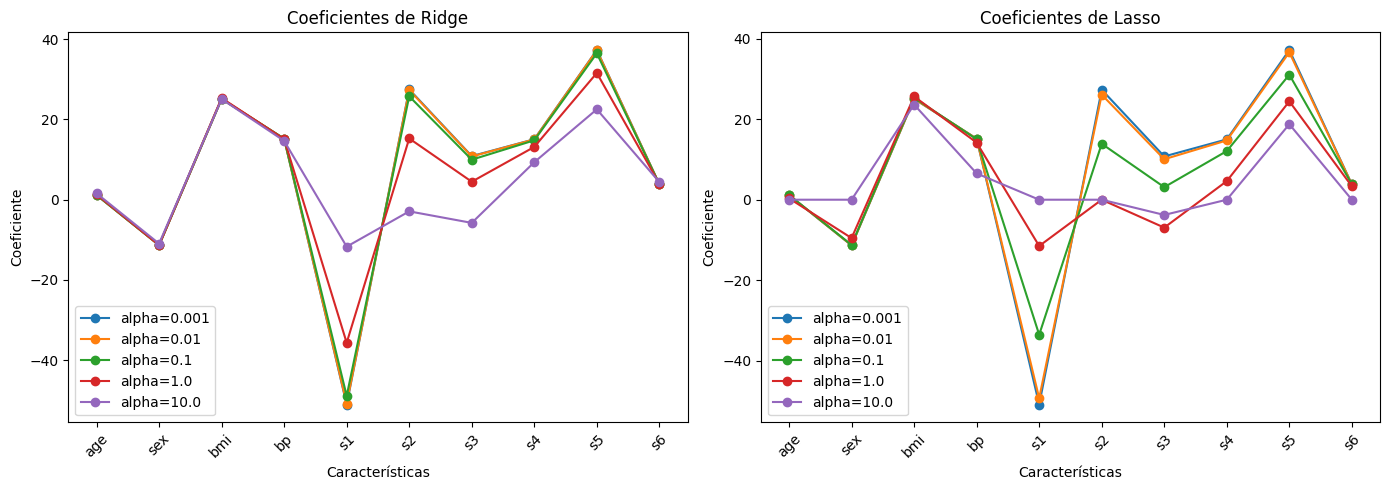

In [39]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, nombre in zip(axes, ["Ridge", "Lasso"]):
    for alpha in alphas:
        modelo = modelos_regularizacion[(nombre, alpha)]
        coeficientes = modelo.named_steps["modelo"].coef_

        ax.plot(
            diabetes.feature_names,
            coeficientes,
            marker="o",
            label=f"alpha={alpha}"
        )

    ax.set_title(f"Coeficientes de {nombre}")
    ax.set_xlabel("Características")
    ax.set_ylabel("Coeficiente")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()


### 3.11 Interpretación

Al aumentar la intensidad de regularización, se penaliza más la magnitud de los coeficientes. En Ridge, esto normalmente reduce sus valores absolutos, mientras que en Lasso puede provocar que algunos coeficientes se vuelvan exactamente cero.

Una regularización mayor puede reducir el sobreajuste, pero si es excesiva puede provocar subajuste y aumentar el error de entrenamiento y validación.

La mejor intensidad no debe elegirse observando únicamente los coeficientes ni el error de entrenamiento. Debemos considerar el error de validación, ya que el objetivo es obtener buenas predicciones en datos no utilizados para ajustar el modelo.

## Identificar los mejores resultados

In [40]:

print("Modelo con menor MAE:")
display(
    tabla_test_reg.loc[
        [tabla_test_reg["MAE"].idxmin()]
    ].round(3)
)

print("Modelo con menor RMSE:")
display(
    tabla_test_reg.loc[
        [tabla_test_reg["RMSE"].idxmin()]
    ].round(3)
)

print("Modelo con mayor R²:")
display(
    tabla_test_reg.loc[
        [tabla_test_reg["R²"].idxmax()]
    ].round(3)
)


Modelo con menor MAE:


,Modelo,MAE,RMSE,R²
7,MLP,41.006,51.819,0.493


Modelo con menor RMSE:


,Modelo,MAE,RMSE,R²
7,MLP,41.006,51.819,0.493


Modelo con mayor R²:


,Modelo,MAE,RMSE,R²
7,MLP,41.006,51.819,0.493


**1. ¿Qué modelo tuvo el mejor desempeño?**

El mejor modelo depende de la métrica utilizada. El menor MAE indica que las predicciones presentan el menor error absoluto promedio, mientras que el menor RMSE favorece al modelo que obtiene el menor error cuadrático medio en su raíz. El mayor R² indica el mejor ajuste relativo respecto a utilizar la media del objetivo como referencia. En este experimento, los ganadores deben identificarse con la tabla de prueba obtenida.

**2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?**

MAE calcula el promedio de los errores absolutos y trata todos los errores proporcionalmente a su magnitud. RMSE eleva los errores al cuadrado antes de promediarlos y calcular la raíz, por lo que penaliza más los errores grandes. Por eso, dos modelos pueden presentar resultados diferentes según la métrica elegida.

**3. ¿Cómo se interpreta un R² negativo?**

Un R² negativo indica que el modelo obtuvo un error cuadrático mayor que el de una predicción de referencia que utiliza la media de los valores reales del conjunto evaluado. Esto significa que el modelo generaliza mal en ese conjunto.

**4. ¿Qué efecto tuvo aumentar la regularización?**

Al aumentar alpha, Ridge y Lasso penalizan con mayor intensidad los coeficientes. Esto puede reducir su magnitud y limitar el sobreajuste. En Lasso, además, puede aumentar el número de coeficientes nulos. Sin embargo, una penalización excesiva puede hacer que el modelo pierda información útil y presente subajuste. El efecto concreto debe comprobarse en los errores y coeficientes obtenidos.

**5. ¿Qué puede explicar los errores grandes?**

Los errores grandes pueden deberse a observaciones difíciles de predecir, variabilidad individual, relaciones no lineales, variables relevantes que no están incluidas en el dataset o limitaciones del modelo. Para comprenderlos mejor es necesario examinar los ejemplos y los gráficos de residuos, sin asumir que una sola observación explica el comportamiento general.

**6. ¿Un coeficiente predictivo demuestra una relación causal?**

No. Un coeficiente predictivo describe cómo se relaciona una característica con las predicciones del modelo, dadas las demás variables y las condiciones del ajuste. No demuestra que esa característica cause un cambio en el objetivo. Para establecer causalidad se necesitan diseños de investigación y métodos adecuados que permitan controlar posibles factores de confusión.

### Conclusión

En esta práctica se compararon ocho modelos de regresión utilizando el dataset Diabetes de scikit-learn. Los modelos se entrenaron con una partición común, se seleccionaron configuraciones mediante validación y se evaluaron finalmente con datos de prueba.

Las métricas MAE, RMSE y R² permitieron analizar diferentes aspectos de la calidad predictiva. Además, los gráficos de valores reales frente a predicciones y los residuos ayudaron a identificar errores y posibles limitaciones de los modelos.

La comparación entre Ridge y Lasso permitió examinar cómo la regularización afecta a los coeficientes, a la selección de características y al error de generalización. Finalmente, el experimento muestra que un modelo más complejo no necesariamente predice mejor y que los resultados predictivos no demuestran relaciones causales.

El modelo más adecuado debe elegirse a partir de los resultados observados, teniendo en cuenta la métrica relevante y su capacidad para generalizar a datos nuevos.